# 01 · Exploratory Data Analysis: CDC Diabetes Health Indicators

**Goal of the project:** predict whether a person has diabetes (or prediabetes) from their answers to a health survey.

**Goal of this notebook:** understand the data *before* building any model:
1. What is in the data?
2. Are there missing values or duplicates?
3. How balanced is the target?
4. Which features show a pattern with diabetes?
5. How strongly is each feature correlated with diabetes?

All findings here are **patterns, not causes**: the data is a survey taken at one point in time.

## 1. Load the data

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook is in notebooks/, so the project folder is one level up.
# Adding it to sys.path lets us import our own code from src/.
PROJECT_DIR = Path.cwd().parent
sys.path.append(str(PROJECT_DIR))

from src.data_loader import load_diabetes_data, VARIABLE_INFO_PATH

FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)

df = load_diabetes_data()   # downloads the first time, then reads the saved CSV

Found saved data, loading diabetes_health_indicators.csv


In [2]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 253,680 rows x 23 columns


,ID,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,0,1,1,1,40,1,0,0,0,0,1,0,1,0,5,18,15,1,0,9,4,3
1,1,0,0,0,0,25,1,0,0,1,0,0,0,0,1,3,0,0,0,0,7,6,1
2,2,0,1,1,1,28,0,0,0,0,1,0,0,1,1,5,30,30,1,0,9,4,8
3,3,0,1,0,1,27,0,0,0,1,1,1,0,1,0,2,0,0,0,0,11,3,6
4,4,0,1,1,1,24,0,0,0,1,1,1,0,1,0,2,3,0,0,0,11,5,4


In [3]:
# Data type of every column
df.dtypes

ID                      int64
Diabetes_binary         int64
HighBP                  int64
HighChol                int64
CholCheck               int64
BMI                     int64
Smoker                  int64
Stroke                  int64
HeartDiseaseorAttack    int64
PhysActivity            int64
Fruits                  int64
Veggies                 int64
HvyAlcoholConsump       int64
AnyHealthcare           int64
NoDocbcCost             int64
GenHlth                 int64
MentHlth                int64
PhysHlth                int64
DiffWalk                int64
Sex                     int64
Age                     int64
Education               int64
Income                  int64
dtype: object

Every column is stored as a whole number (`int64`). Even "Yes/No" answers are stored as **0 / 1**,
and ordered answers (age group, income, general health) are stored as **codes** such as 1 to 13.
So the numbers are often *categories*, not measurements. For example, `Age = 9` means "60–64 years", not 9 years old.

Each row is **one person** who answered the CDC's 2015 BRFSS telephone health survey.

In [4]:
# The official description of every column, saved by data_loader.py
variable_info = pd.read_csv(VARIABLE_INFO_PATH)
variable_info[["name", "role", "type", "description"]]

,name,role,type,description
0,ID,ID,Integer,Patient ID
1,Diabetes_binary,Target,Binary,0 = no diabetes 1 = prediabetes or diabetes
2,HighBP,Feature,Binary,0 = no high BP 1 = high BP
3,HighChol,Feature,Binary,0 = no high cholesterol 1 = high cholesterol
4,CholCheck,Feature,Binary,0 = no cholesterol check in 5 years 1 = yes ch...
5,BMI,Feature,Integer,Body Mass Index
6,Smoker,Feature,Binary,Have you smoked at least 100 cigarettes in you...
7,Stroke,Feature,Binary,(Ever told) you had a stroke. 0 = no 1 = yes
8,HeartDiseaseorAttack,Feature,Binary,coronary heart disease (CHD) or myocardial inf...
9,PhysActivity,Feature,Binary,physical activity in past 30 days - not includ...


### What each column means

| Column | Type | Meaning (from `variable_info.csv`) |
|---|---|---|
| `ID` | ID | Row number for each respondent. Not used for analysis. |
| **`Diabetes_binary`** | **Target** | **0 = no diabetes, 1 = prediabetes or diabetes** |
| `HighBP` | Yes/No | Has been told they have high blood pressure |
| `HighChol` | Yes/No | Has been told they have high cholesterol |
| `CholCheck` | Yes/No | Had a cholesterol check in the last 5 years |
| `BMI` | Number | Body Mass Index (weight relative to height) |
| `Smoker` | Yes/No | Has smoked at least 100 cigarettes in their life |
| `Stroke` | Yes/No | Has ever been told they had a stroke |
| `HeartDiseaseorAttack` | Yes/No | Has coronary heart disease or has had a heart attack |
| `PhysActivity` | Yes/No | Did physical activity in the past 30 days (not counting their job) |
| `Fruits` | Yes/No | Eats fruit at least once a day |
| `Veggies` | Yes/No | Eats vegetables at least once a day |
| `HvyAlcoholConsump` | Yes/No | Heavy drinker (men > 14 drinks a week, women > 7) |
| `AnyHealthcare` | Yes/No | Has any health insurance or health care coverage |
| `NoDocbcCost` | Yes/No | In the past year, needed a doctor but couldn't go because of cost |
| `GenHlth` | Scale 1–5 | Self-rated general health: 1 = excellent … 5 = poor |
| `MentHlth` | Days 0–30 | Days in the past 30 when mental health was not good |
| `PhysHlth` | Days 0–30 | Days in the past 30 when physical health was not good |
| `DiffWalk` | Yes/No | Has serious difficulty walking or climbing stairs |
| `Sex` | 0/1 | 0 = female, 1 = male |
| `Age` | Code 1–13 | Age group in 5-year bands: 1 = 18–24, 9 = 60–64, 13 = 80 or older |
| `Education` | Code 1–6 | 1 = never attended school … 6 = college graduate |
| `Income` | Code 1–8 | Household income: 1 = less than \$10,000 … 8 = \$75,000 or more |

For Yes/No columns, **0 = No and 1 = Yes**.

In [5]:
# The ID is just a row number, so we drop it. It carries no information about health.
df = df.drop(columns="ID")

## 2. Missing values and duplicates

In [6]:
# Count missing values in each column
missing = df.isna().sum()
print(f"Total missing values: {missing.sum()}")

Total missing values: 0


**There are no missing values.** The UCI version of this dataset was already cleaned by its authors,
so we don't need to fill or drop anything.

In [7]:
# A duplicate is a row where EVERY answer is the same as another row.
n_duplicates = df.duplicated().sum()
print(f"Duplicate rows: {n_duplicates:,} ({n_duplicates / len(df):.1%} of all rows)")

# Is the diabetes rate different among the duplicated rows?
is_dup = df.duplicated(keep=False)   # keep=False marks every copy, not just the 2nd, 3rd...
print(f"Diabetes rate in duplicated rows: {df.loc[is_dup, 'Diabetes_binary'].mean():.1%}")
print(f"Diabetes rate in all other rows:  {df.loc[~is_dup, 'Diabetes_binary'].mean():.1%}")

Duplicate rows: 24,206 (9.5% of all rows)


Diabetes rate in duplicated rows: 1.3%
Diabetes rate in all other rows:  16.0%


**About 24,000 rows (9.5%) are exact copies of another row.** Should we remove them?

**For this EDA we keep them**, because they describe the real survey population:
- **They are most likely different people, not data-entry errors.** Each row had its own ID. Most columns are
  Yes/No, so many people give exactly the same answers. A healthy young adult who exercises, doesn't smoke and
  has no conditions has a very common answer pattern.
- **This shows in the numbers.** Only about 1% of duplicated rows have diabetes, compared with about 16% of the
  other rows. The duplicates are mostly people with a common "healthy" profile.
- **Removing them would distort the data.** We would delete thousands of real healthy people, and the dataset
  would look as if diabetes were more common than it is.

**For modelling we will remove them** (in `02_preprocessing.ipynb`). Identical rows could land in both the
training and the test set, so the model would be tested on answers it has already seen, which makes the test score look too good.

## 3. The target: how many people have diabetes?

In [8]:
counts = df["Diabetes_binary"].value_counts().sort_index()
target_table = pd.DataFrame({
    "label": ["No diabetes (0)", "Prediabetes or diabetes (1)"],
    "people": counts.values,
    "percent": (counts.values / len(df) * 100).round(1),
})
target_table

,label,people,percent
0,No diabetes (0),218334,86.1
1,Prediabetes or diabetes (1),35346,13.9


In [9]:
# Style shared by every chart in this notebook
BLUE = "#2a78d6"      # main colour
ORANGE = "#d9822b"    # second colour, used only when two groups must be told apart
GREY = "#898781"      # reference lines and secondary text

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e1e0d9",
    "axes.axisbelow": True,
    "font.size": 11,
})

overall_rate = df["Diabetes_binary"].mean()   # share of people with diabetes, used as a reference line


def save_chart(fig, filename):
    """Save a chart to reports/figures/ at a good resolution."""
    fig.savefig(FIGURES_DIR / filename, dpi=150, bbox_inches="tight")
    print(f"Saved reports/figures/{filename}")

Saved reports/figures/target_class_balance.png


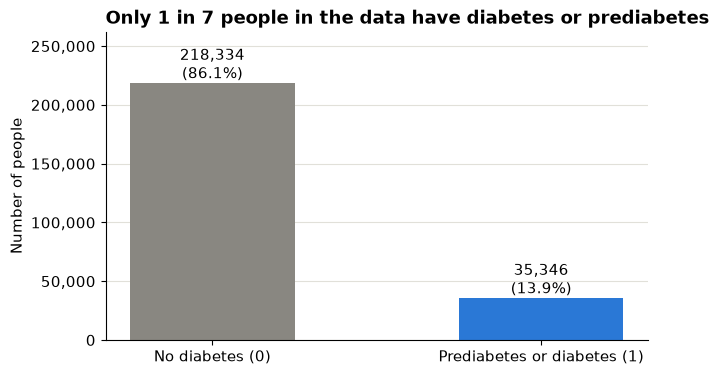

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(target_table["label"], target_table["people"], color=[GREY, BLUE], width=0.5)

# Write the count and percentage on top of each bar
for bar, people, pct in zip(bars, target_table["people"], target_table["percent"]):
    ax.text(bar.get_x() + bar.get_width() / 2, people, f"{people:,}\n({pct}%)",
            ha="center", va="bottom")

ax.set_title("Only 1 in 7 people in the data have diabetes or prediabetes", loc="left", fontweight="bold")
ax.set_ylabel("Number of people")
ax.set_ylim(0, target_table["people"].max() * 1.2)
ax.yaxis.set_major_formatter(lambda v, pos: f"{v:,.0f}")
save_chart(fig, "target_class_balance.png")
plt.show()

### Class imbalance, and why accuracy alone will be misleading

About **86%** of people have no diabetes and only about **14%** do. This is called **class imbalance**:
one class is much bigger than the other.

**Why this matters for the model:** imagine a "model" that ignores the data and always says *"no diabetes"*.
It would be right for every person without diabetes, so its **accuracy would be about 86%**, which sounds good.
But it would **miss every single person with diabetes**, which is the group we care about.

So accuracy alone is misleading. When we evaluate the models, we will also look at:
- **Recall:** of the people who really have diabetes, how many did the model find?
- **Precision:** of the people the model flagged, how many really have diabetes?
- **ROC-AUC:** how well the model ranks people with diabetes above people without, across all thresholds.

An 86% accuracy score is our **baseline to beat**, not an achievement.

## 4. Diabetes rate across key features

For each feature we ask: *in each group, what share of people have diabetes?*
The grey dashed line is the overall rate (about 14%), so bars above it are groups with a higher rate than average.

In [11]:
def diabetes_rate(data, column):
    """Share of people with diabetes, and number of people, in each group of a column."""
    return data.groupby(column)["Diabetes_binary"].agg(rate="mean", people="size")


def plot_rate(table, labels, title, xlabel, filename, rotate=0):
    """Bar chart of the diabetes rate per group, with a line for the overall rate."""
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(labels, table["rate"], color=BLUE, width=0.65)
    ax.axhline(overall_rate, color=GREY, linestyle="--", linewidth=1.2)
    ax.text(1.01, overall_rate, f"overall\n{overall_rate:.1%}", color=GREY,
            transform=ax.get_yaxis_transform(), va="center")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Share with diabetes")
    ax.yaxis.set_major_formatter(lambda v, pos: f"{v:.0%}")
    plt.setp(ax.get_xticklabels(), rotation=rotate, ha="right" if rotate else "center")
    save_chart(fig, filename)
    plt.show()

### 4.1 BMI

BMI has 84 different values, too many for one bar each. We group it into the standard **WHO weight categories**
so each bar has enough people to be reliable.

                       rate  people
BMI_category                       
Underweight\n(<18.5)   5.4%    3127
Healthy\n(18.5–25)     5.7%   68953
Overweight\n(25–30)   11.4%   93749
Obese I\n(30–35)      19.2%   53451
Obese II\n(35–40)     27.4%   20663
Obese III\n(40+)      33.5%   13737


Saved reports/figures/diabetes_rate_by_bmi.png


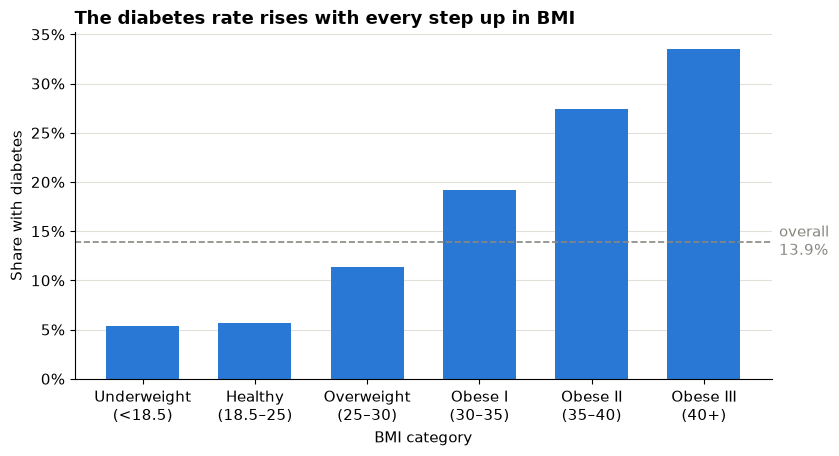

In [12]:
bmi_bins = [0, 18.5, 25, 30, 35, 40, np.inf]
bmi_labels = ["Underweight\n(<18.5)", "Healthy\n(18.5–25)", "Overweight\n(25–30)",
              "Obese I\n(30–35)", "Obese II\n(35–40)", "Obese III\n(40+)"]

# right=False means each bin includes its left edge: 25 counts as "Overweight", not "Healthy"
df["BMI_category"] = pd.cut(df["BMI"], bins=bmi_bins, labels=bmi_labels, right=False)

bmi_rate = diabetes_rate(df, "BMI_category")
print(bmi_rate.assign(rate=bmi_rate["rate"].map("{:.1%}".format)))

plot_rate(bmi_rate, bmi_labels, "The diabetes rate rises with every step up in BMI",
          "BMI category", "diabetes_rate_by_bmi.png")

**Pattern:** the rate is about **6%** for underweight and healthy-weight people, then climbs with each category:
11% for overweight, 19% for obese I, 27% for obese II and **34% for obese III**, more than five times the healthy-weight rate.

### 4.2 Age

Saved reports/figures/diabetes_rate_by_age.png


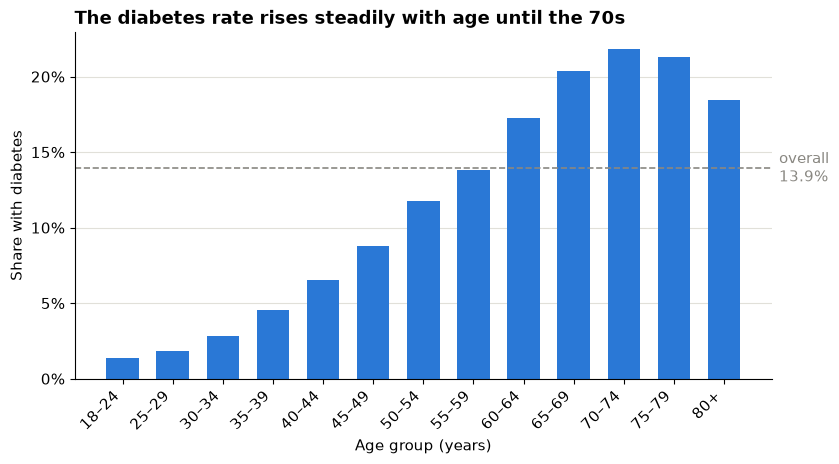

In [13]:
age_labels = ["18–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54",
              "55–59", "60–64", "65–69", "70–74", "75–79", "80+"]

age_rate = diabetes_rate(df, "Age")
plot_rate(age_rate, age_labels, "The diabetes rate rises steadily with age until the 70s",
          "Age group (years)", "diabetes_rate_by_age.png", rotate=45)

**Pattern:** the rate is under **2%** for 18–29 year olds and rises steadily, peaking at about **22%** for
ages 70–74. It dips slightly for the oldest groups (about 18.5% for 80+).

### 4.3 General health (self-rated)

Saved reports/figures/diabetes_rate_by_general_health.png


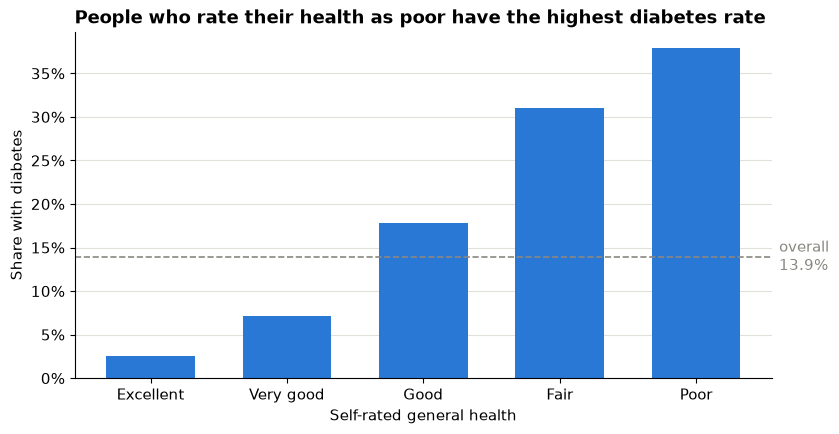

In [14]:
health_labels = ["Excellent", "Very good", "Good", "Fair", "Poor"]

health_rate = diabetes_rate(df, "GenHlth")
plot_rate(health_rate, health_labels, "People who rate their health as poor have the highest diabetes rate",
          "Self-rated general health", "diabetes_rate_by_general_health.png")

**Pattern:** the worse people rate their own health, the higher the diabetes rate: from about **2.5%**
for "excellent" to about **38%** for "poor". This is the steepest pattern of all the features.
Note that this works both ways: people who already know they have diabetes may rate their health lower *because* of it.

### 4.4 Income

Saved reports/figures/diabetes_rate_by_income.png


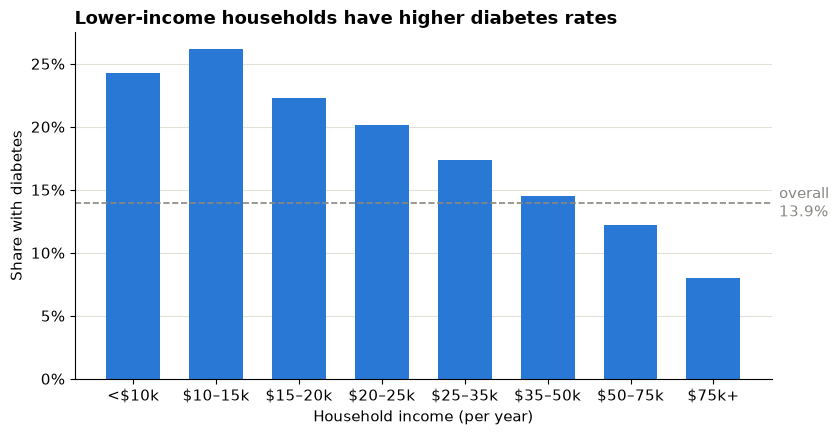

In [15]:
income_labels = ["<$10k", "$10–15k", "$15–20k", "$20–25k", "$25–35k", "$35–50k", "$50–75k", "$75k+"]

income_rate = diabetes_rate(df, "Income")
plot_rate(income_rate, income_labels, "Lower-income households have higher diabetes rates",
          "Household income (per year)", "diabetes_rate_by_income.png")

**Pattern:** the rate is about **24–26%** in the lowest income groups and falls steadily to **8%** for
households earning \$75,000 or more. Income is linked to many other things (age, access to care, diet),
so this does not show that income itself affects diabetes.

### 4.5 Yes/No health features: high blood pressure, high cholesterol, physical activity

These three columns only have two values, so we plot them side by side.

Saved reports/figures/diabetes_rate_by_health_conditions.png


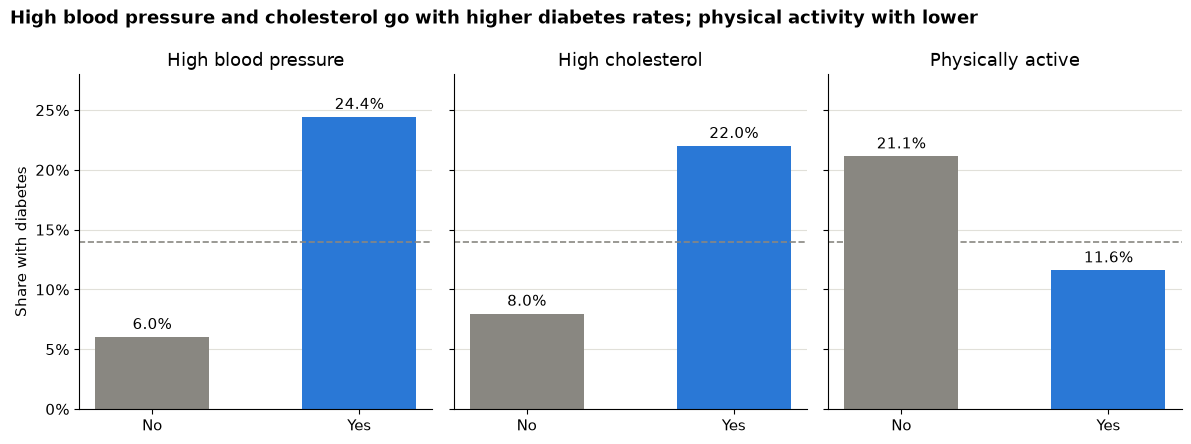

In [16]:
yes_no_features = {
    "HighBP": "High blood pressure",
    "HighChol": "High cholesterol",
    "PhysActivity": "Physically active",
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharey=True)

for ax, (column, name) in zip(axes, yes_no_features.items()):
    table = diabetes_rate(df, column)
    bars = ax.bar(["No", "Yes"], table["rate"], color=[GREY, BLUE], width=0.55)
    ax.bar_label(bars, labels=[f"{r:.1%}" for r in table["rate"]], padding=3)
    ax.axhline(overall_rate, color=GREY, linestyle="--", linewidth=1.2)
    ax.set_title(name)
    ax.yaxis.set_major_formatter(lambda v, pos: f"{v:.0%}")

axes[0].set_ylabel("Share with diabetes")
axes[0].set_ylim(0, 0.28)   # extra headroom so the labels don't touch the panel titles
fig.suptitle("High blood pressure and cholesterol go with higher diabetes rates; physical activity with lower",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_chart(fig, "diabetes_rate_by_health_conditions.png")
plt.show()

**Patterns:**
- **High blood pressure:** about **24%** have diabetes, compared with **6%** of people without it.
- **High cholesterol:** about **22%**, compared with **8%**.
- **Physical activity:** active people have a *lower* rate, about **12%** compared with **21%** for inactive people.

## 5. Correlation of each feature with diabetes

Correlation is a number from −1 to +1:
- **Positive:** higher values of the feature go with *more* diabetes.
- **Negative:** higher values go with *less* diabetes.
- **Near 0:** no straight-line relationship.

Many of our features are Yes/No or ordered codes, so the correlation is only a rough guide to how strongly
each one is linked to diabetes. It can't capture non-straight patterns (like age dipping after 75).

In [17]:
# Correlate every original feature with the target (we skip the BMI_category we created)
features = df.drop(columns=["Diabetes_binary", "BMI_category"])
correlations = features.corrwith(df["Diabetes_binary"]).sort_values()

print("Strongest positive:")
print(correlations.tail(5).sort_values(ascending=False).round(3))
print("\nStrongest negative:")
print(correlations.head(3).round(3))

Strongest positive:
GenHlth     0.294
HighBP      0.263
DiffWalk    0.218
BMI         0.217
HighChol    0.200
dtype: float64

Strongest negative:
Income         -0.164
Education      -0.124
PhysActivity   -0.118
dtype: float64


Saved reports/figures/feature_correlation_with_diabetes.png


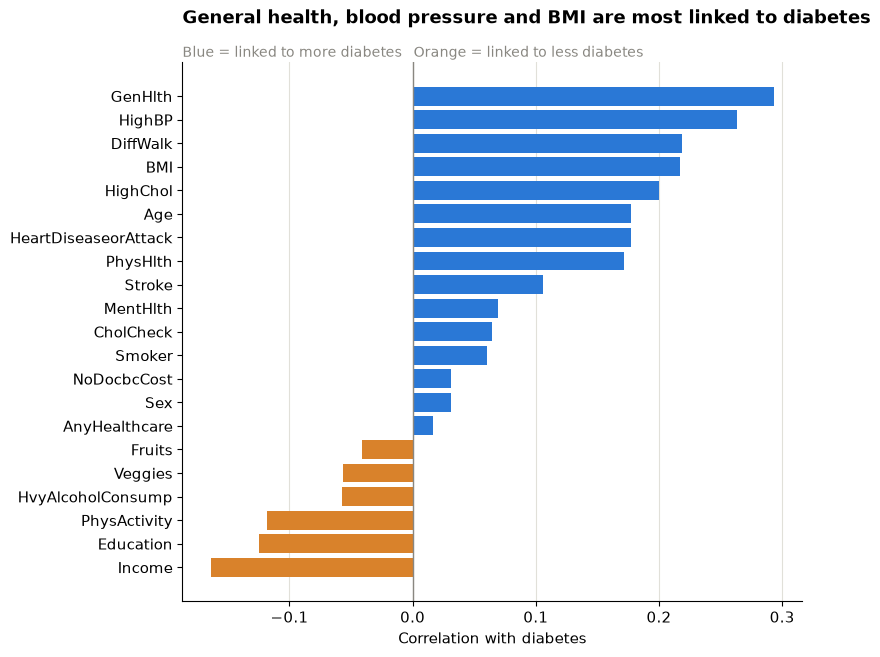

In [18]:
fig, ax = plt.subplots(figsize=(8, 7))
colours = [BLUE if value > 0 else ORANGE for value in correlations]
ax.barh(correlations.index, correlations.values, color=colours)
ax.axvline(0, color=GREY, linewidth=1)

ax.set_title("General health, blood pressure and BMI are most linked to diabetes",
             loc="left", fontweight="bold", pad=28)   # pad leaves room for the colour key below the title
ax.text(0, 1.01, "Blue = linked to more diabetes   Orange = linked to less diabetes",
        transform=ax.transAxes, color=GREY, fontsize=10)
ax.set_xlabel("Correlation with diabetes")
ax.grid(axis="x", color="#e1e0d9")
ax.grid(axis="y", visible=False)
save_chart(fig, "feature_correlation_with_diabetes.png")
plt.show()

**Pattern:** the features most linked to diabetes are **general health** (0.29), **high blood pressure** (0.26),
**difficulty walking** (0.22), **BMI** (0.22) and **high cholesterol** (0.20). **Income** (−0.16),
**education** (−0.12) and **physical activity** (−0.12) are linked to *lower* diabetes rates.

No single feature is strongly correlated with diabetes (all are below 0.3). This suggests a model will need to
**combine many features** to predict well.

## 6. Charts saved

In [19]:
# List every chart this notebook saved
for path in sorted(FIGURES_DIR.glob("*.png")):
    print(path.name)

diabetes_rate_by_age.png
diabetes_rate_by_bmi.png
diabetes_rate_by_general_health.png
diabetes_rate_by_health_conditions.png
diabetes_rate_by_income.png
feature_correlation_with_diabetes.png
target_class_balance.png


## 7. EDA summary

- **The data is clean but imbalanced.** 253,680 survey answers, no missing values. Only **13.9%** have diabetes
  or prediabetes, so a model that always says "no" would already score about 86% accuracy. We will judge
  models with recall, precision and ROC-AUC, not accuracy alone.
- **Duplicates are real people, but will be removed for modelling.** About 9.5% of rows are identical. They are
  most likely different people with the same common, mostly healthy answers, so we kept them to describe the data.
  We remove them before modelling so the test score stays fair.
- **Weight and age show strong patterns.** The diabetes rate rises from about 6% at a healthy BMI to 34% at
  BMI 40+, and from under 2% for under-30s to about 22% for people in their early 70s.
- **Health conditions go together.** People with high blood pressure (24% vs 6%), high cholesterol (22% vs 8%),
  or poor self-rated health (38% vs 2.5% for excellent) have much higher diabetes rates. Physically active people
  and higher-income households have lower rates.
- **No single feature is enough.** The strongest correlation is only 0.29 (general health), so the model will
  need to combine several features. These are patterns in survey data, not proof that any feature causes diabetes.